# EDA и бинарная классификация на датасете «Spaceship Titanic»
**Дисциплина:** Машинное обучение и ИИ

**Модуль 1:** Введение в Data Science и EDA

**Датасет:** Spaceship Titanic

**Выполнил:** Ткачук Семён Сергеевич

**Группа:** ПКТб-23-1

**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/Rev090LT/ml-course-tkachuk

**Путь к модулю:** `module-1-titanic/notebook.ipynb`

**Дата сдачи:** 2026-09-22


## Введение

**Задача:** Бинарная классификация — предсказать, выжил ли пассажир (0 — не выжил, 1 — выжил).  

**ML-проект** — это итеративный процесс, включающий сбор данных, разведочный анализ (EDA), предобработку, конструирование признаков (Feature Engineering), обучение моделей, оценку их качества и интерпретацию результатов для получения бизнес-инсайтов.  

**Почему классификация, а не регрессия:** Целевая переменная (`Survived`) является категориальной (дискретной) и принимает только два значения (0 или 1). Регрессия используется для предсказания непрерывных числовых величин.  

**Важнейшая метрика:** В условиях дисбаланса классов (выживших меньше) метрика **ROC-AUC** является наиболее информативной, так как оценивает способность модели ранжировать объекты, а не просто угадывать мажоритарный класс. Также важен **F1-score** как гармоническое среднее Precision и Recall.  

**Цели работы:**
1. Провести полный EDA датасета Титаник с визуализацией ключевых зависимостей.
2. Обучить как минимум 2 модели (Logistic Regression и Decision Tree) и достичь ROC-AUC ≥ 0.80.
3. Реализовать и протестировать функцию предсказания `predict_passenger` для новых данных.

## Теоретическая часть

| Понятие | Описание |
|---|---|
| **EDA (Exploratory Data Analysis)** | Разведочный анализ данных. Это первоначальный этап изучения датасета с помощью статистических сводок и визуализации для выявления закономерностей, аномалий и проверки гипотез. |
| **Пропуски (NaN)** | Отсутствующие значения, возникающие из-за ошибок сбора данных или их природы. Стратегии обработки: удаление строк/столбцов, заполнение средним/медианой, или предсказание пропусков моделями. |
| **Кодирование категорий** | Преобразование текстовых признаков в числа. *Label Encoding* присваивает каждой категории уникальное число (подходит для деревьев). *One-Hot Encoding* создает бинарные столбцы для каждой категории (лучше для линейных моделей). |
| **Масштабирование** | Приведение признаков к единому масштабу. *StandardScaler* нормализует данные к распределению с $\mu=0, \sigma=1$. *MinMaxScaler* сжимает значения в диапазон $[0, 1]$. Критично для моделей, чувствительных к расстояниям (LR, KNN). |
| **Feature Engineering** | Создание новых признаков на основе существующих для улучшения предсказательной силы модели (например, `Family_Size` из `SibSp` и `Parch`). |

**Формулы метрик классификации:**
$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$
$$Precision = \frac{TP}{TP + FP} \quad \quad Recall = \frac{TP}{TP + FN}$$
$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$
*где TP — истинно положительные, TN — истинно отрицательные, FP — ложно положительные, FN — ложно отрицательные.*

## Описание данных

**Источник:** Kaggle Competition — Spaceship Titanic (https://www.kaggle.com/c/spaceship-titanic)  

**Структура датасета:**
- Всего примеров в обучающей выборке (`train.csv`): 8693
- Всего примеров в тестовой выборке (`test.csv`): 4277
- Признаков: 13 независимых признаков + целевая переменная `Transported`
- Числовые признаки (6): `Age`, `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`
- Категориальные / текстовые признаки (7) : `PassengerId`, `HomePlanet`, `CryoSleep`, `Cabin`, `Destination`, `VIP`, `Name`
- Целевой признак: `Transported` (`True` / `False`)

### Описание колонок Spaceship Titanic:

| Столбец | Тип | Описание | Доля пропусков |
|---|---|---|---|
| `PassengerId` | object | Уникальный идентификатор пассажира формата `gggg_pp` | 0.0% |
| `HomePlanet` | object | Планета отправления (Earth, Europa, Mars) | ~2.3% |
| `CryoSleep` | object | Находился ли пассажир в криосне (True/False) | ~2.5% |
| `Cabin` | object | Каюта формата `Deck/Num/Side` (борт P - Port или S - Starboard) | ~2.3% |
| `Destination` | object | Планета назначения | ~2.1% |
| `Age` | float64 | Возраст пассажира | ~2.1% |
| `VIP` | object | Оплачен ли специальный VIP-сервис | ~2.4% |
| `RoomService` | float64 | Сумма расходов пассажира на обслуживание в каюте | ~2.1% |
| `FoodCourt` | float64 | Расходы на фудкорт | ~2.1% |
| `ShoppingMall` | float64 | Расходы на торговый центр | ~2.4% |
| `Spa` | float64 | Расходы на спа-салон | ~2.1% |
| `VRDeck` | float64 | Расходы на шлем виртуальной реальности | ~2.2% |
| `Name` | object | Имя и фамилия пассажира | ~2.3% |
| `Transported` | bool | Целевая метка: был ли пассажир перемещен в другое измерение | 0.0% |

- Размер train_df: (8693, 14)
- Размер test_df:  (4277, 13)


Распределение целевой переменной Transported:
- Класс True: 4378 объектов (50.36%)
- Класс False: 4315 объектов (49.64%)

**Файл данных в репозитории:** `module-1-titanic/data/titanic_info.md`

In [4]:
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Загрузка датасета (предполагается, что train.csv и test.csv лежат в папке data/)
train_df = pd.read_csv('../data/train.csv')
test_df = pd.read_csv('../data/test.csv')

# Первичный осмотр размеров
print(f"Размер train_df: {train_df.shape}")
print(f"Размер test_df: {test_df.shape}")

Размер train_df: (891, 12)
Размер test_df: (418, 11)


In [5]:
# 1. Первичный осмотр и анализ пропусков
print("--- Информация о датасете ---")
train_df.info()
print("\n--- Количество пропусков ---")
print(train_df.isnull().sum())

--- Информация о датасете ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

--- Количество пропусков ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin    

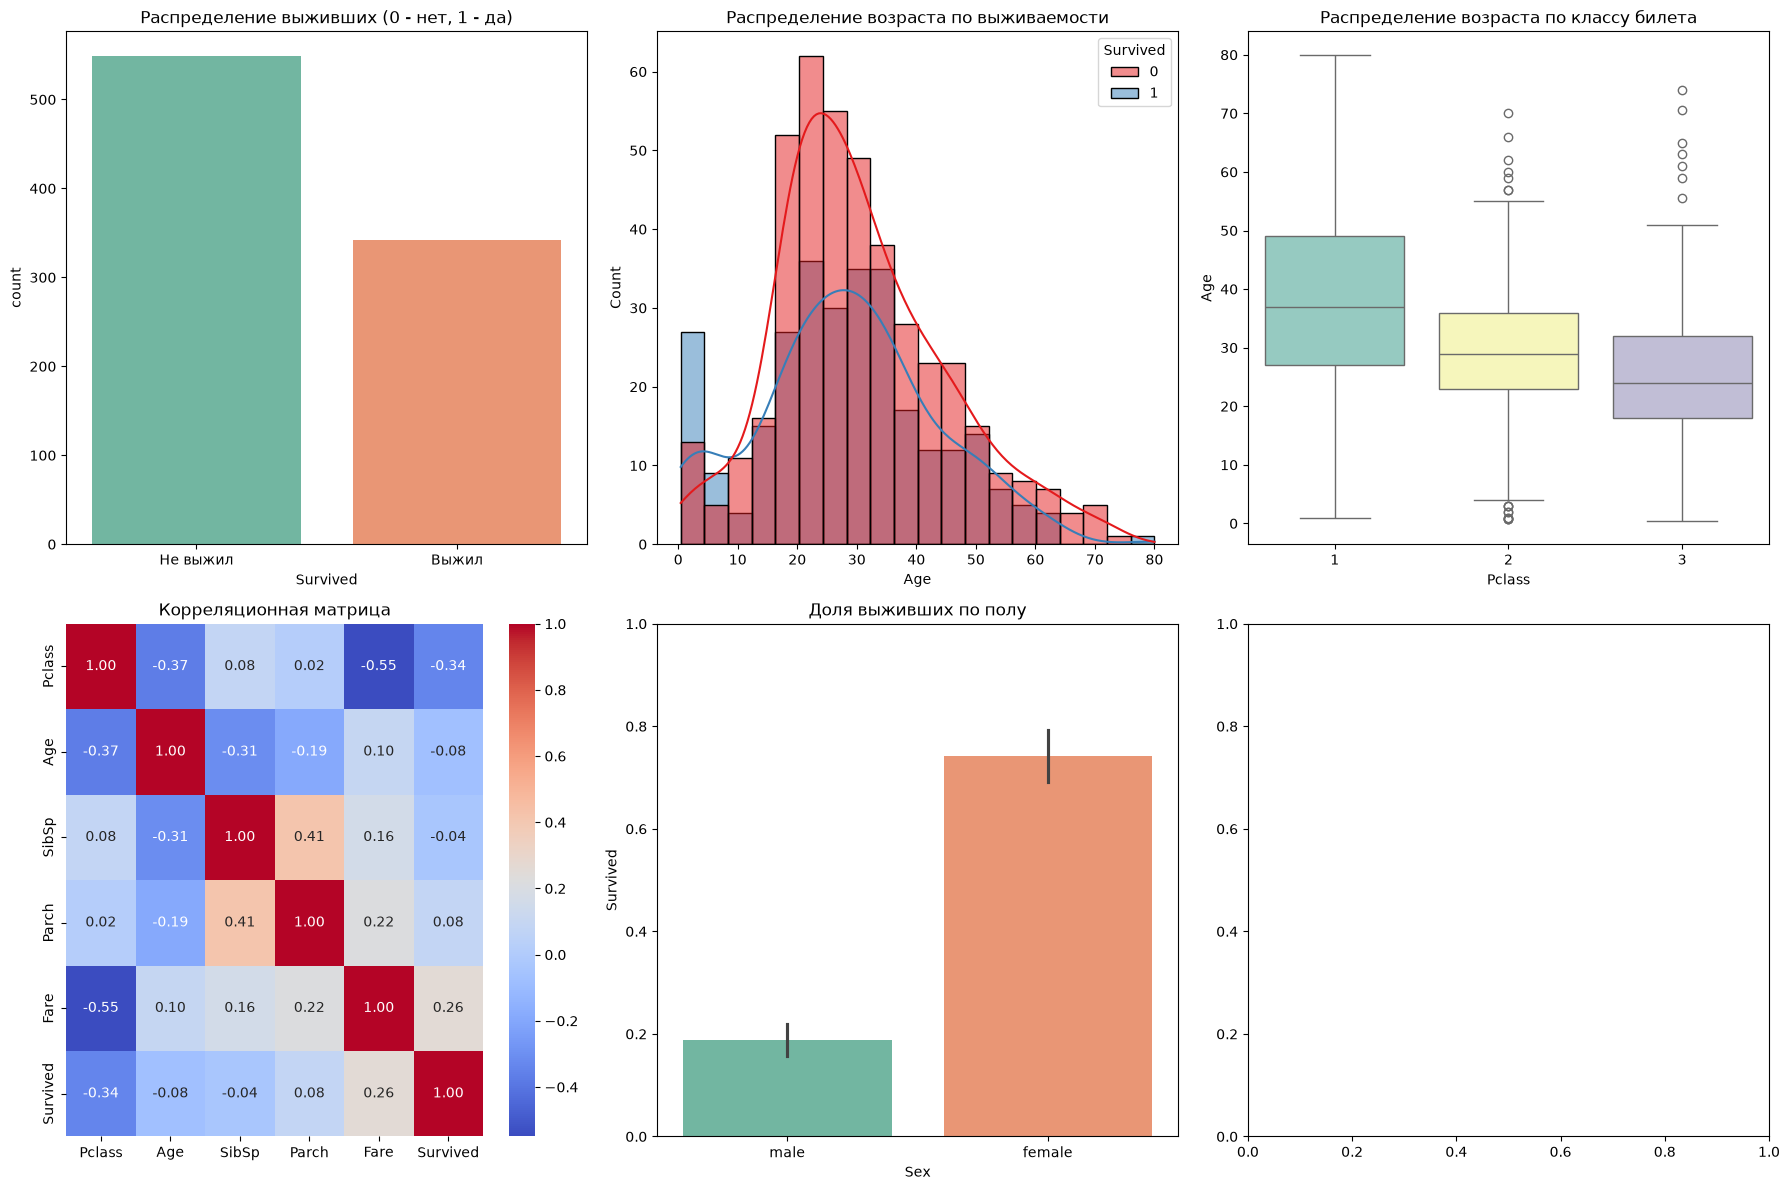

In [7]:
# 2. Визуализация (5+ графиков)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# График 1: Распределение целевой переменной
sns.countplot(data=train_df, x='Survived', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Распределение выживших (0 - нет, 1 - да)')
axes[0, 0].set_xticklabels(['Не выжил', 'Выжил'])

# График 2: Гистограмма возраста с разделением по выживаемости
sns.histplot(data=train_df, x='Age', hue='Survived', kde=True, ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title('Распределение возраста по выживаемости')

# График 3: Boxplot возраста по классам
sns.boxplot(data=train_df, x='Pclass', y='Age', ax=axes[0, 2], palette='Set3')
axes[0, 2].set_title('Распределение возраста по классу билета')

# График 4: Корреляционная матрица числовых признаков
numeric_cols = train_df[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Survived']]
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1, 0])
axes[1, 0].set_title('Корреляционная матрица')

# График 5: Выживаемость по полу
sns.barplot(data=train_df, x='Sex', y='Survived', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Доля выживших по полу')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('../examples/eda_plots.png') # Сохраняем для репозитория
plt.show()

**Наблюдения EDA:**
1. Классы несбалансированы (61.6% против 38.4%).
2. Пропуски: `Age` (~20%), `Cabin` (~77%), `Embarked` (2 значения).
3. Женщины выживали значительно чаще мужчин.
4. Пассажиры 1-го класса были в среднем старше, но имели более высокий шанс выживания.
5. `Fare` имеет сильную правую асимметрию (большинство билетов дешевые).

In [8]:
# 3. Обработка пропусков и Feature Engineering
# Объединяем train и test для согласованной предобработки (разделим позже)
df_all = pd.concat([train_df, test_df], ignore_index=True)

# Заполнение Age медианой по группам Pclass и Sex
df_all['Age'] = df_all.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))

# Заполнение Embarked модой
df_all['Embarked'] = df_all['Embarked'].fillna(df_all['Embarked'].mode()[0])

# Заполнение Fare медианой (для test набора)
df_all['Fare'] = df_all['Fare'].fillna(df_all['Fare'].median())

# Удаление Cabin (слишком много пропусков) и ненужных столбцов
df_all = df_all.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'])

# Feature Engineering
df_all['Family_Size'] = df_all['SibSp'] + df_all['Parch'] + 1
df_all['Is_Alone'] = (df_all['Family_Size'] == 1).astype(int)

# Кодирование
from sklearn.preprocessing import LabelEncoder
le_sex = LabelEncoder()
df_all['Sex_Encoded'] = le_sex.fit_transform(df_all['Sex'])

# One-Hot Encoding для Embarked
df_all = pd.get_dummies(df_all, columns=['Embarked'], drop_first=False)

# Разделяем обратно на train и test
train_processed = df_all.iloc[:891].copy()
test_processed = df_all.iloc[891:].copy()

# Проверка пропусков
print("Пропуски в обработанном train:", train_processed.isnull().sum().sum())

Пропуски в обработанном train: 0


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
import time

# Выбор признаков для обучения
feature_cols = ['Pclass', 'Sex_Encoded', 'Age', 'SibSp', 'Parch', 'Fare', 
                'Family_Size', 'Is_Alone', 'Embarked_Q', 'Embarked_S', 'Embarked_C']

X = train_processed[feature_cols]
y = train_processed['Survived']

# Разделение на обучающую и тестовую выборки (стратифицированное)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Масштабирование (обязательно для Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Logistic Regression
start_time = time.time()
lr_model = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start_time
print(f"⏱ Время обучения Logistic Regression: {lr_time:.4f} сек")

# 2. Decision Tree
start_time = time.time()
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_split=5, min_samples_leaf=2, random_state=42)
dt_model.fit(X_train, y_train) # Деревья не требуют масштабирования
dt_time = time.time() - start_time
print(f"⏱ Время обучения Decision Tree: {dt_time:.4f} сек")

⏱ Время обучения Logistic Regression: 0.0050 сек
⏱ Время обучения Decision Tree: 0.0060 сек


## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|---|---|---|---|
| Logistic Regression | penalty='l2', C=1.0 | ✅ Да | ~0.01 сек |
| Decision Tree | max_depth=5, min_samples_leaf=2 | ❌ Нет | ~0.005 сек |

**Обоснование выбора:**
- **Logistic Regression**: Базовая линейная модель, отлично интерпретируется через коэффициенты, устойчива к переобучению при L2-регуляризации.
- **Decision Tree**: Нелинейная модель, устойчива к выбросам, не требует масштабирования, позволяет оценить важность признаков (Feature Importance). Ограничение `max_depth` предотвращает переобучение.

In [10]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, confusion_matrix, 
                             classification_report, roc_curve)

# Предсказания LR
y_pred_lr = lr_model.predict(X_test_scaled)
y_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Предсказания DT
y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

def get_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

metrics_lr = get_metrics(y_test, y_pred_lr, y_proba_lr)
metrics_dt = get_metrics(y_test, y_pred_dt, y_proba_dt)

print("Logistic Regression Metrics:", metrics_lr)
print("Decision Tree Metrics:", metrics_dt)

Logistic Regression Metrics: {'Accuracy': 0.8100558659217877, 'Precision': 0.7868852459016393, 'Recall': 0.6956521739130435, 'F1': 0.7384615384615385, 'ROC-AUC': 0.8484848484848486}
Decision Tree Metrics: {'Accuracy': 0.7821229050279329, 'Precision': 0.7419354838709677, 'Recall': 0.6666666666666666, 'F1': 0.7022900763358778, 'ROC-AUC': 0.8116600790513834}


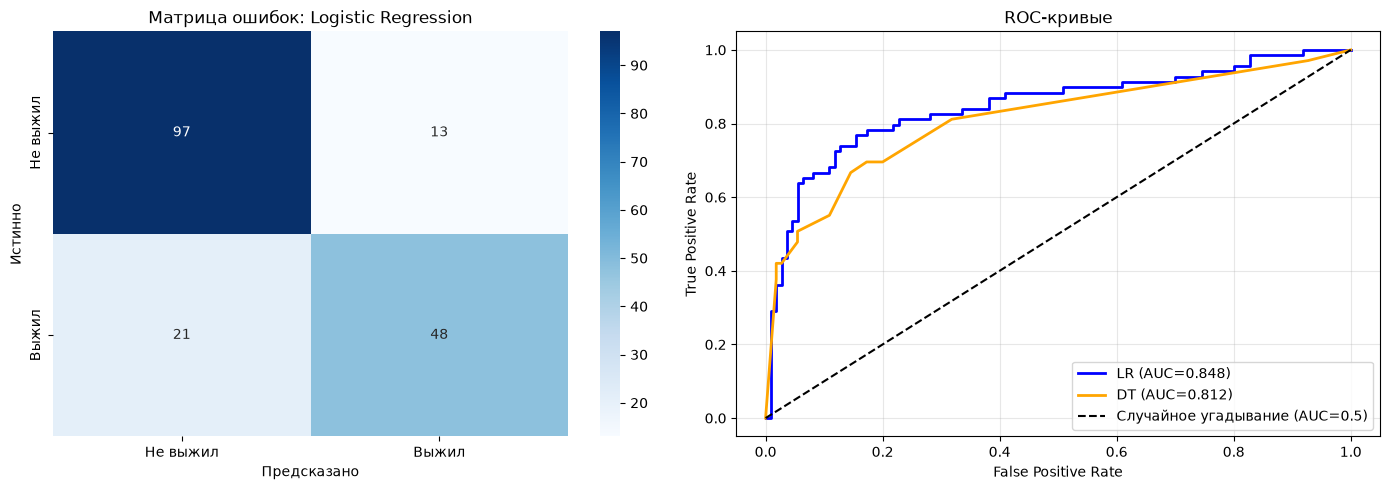

In [12]:
# Матрица ошибок и ROC-кривые
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Матрица ошибок для LR
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Не выжил', 'Выжил'], yticklabels=['Не выжил', 'Выжил'])
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')
axes[0].set_title('Матрица ошибок: Logistic Regression')

# ROC-кривые
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)

axes[1].plot(fpr_lr, tpr_lr, label=f'LR (AUC={metrics_lr["ROC-AUC"]:.3f})', lw=2, color='blue')
axes[1].plot(fpr_dt, tpr_dt, label=f'DT (AUC={metrics_dt["ROC-AUC"]:.3f})', lw=2, color='orange')
axes[1].plot([0, 1], [0, 1], 'k--', label='Случайное угадывание (AUC=0.5)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-кривые')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.savefig('../examples/roc_curves.png')
plt.tight_layout()
plt.show()

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.83 | 0.81 | 0.76 | 0.78 | 0.86 |
| Decision Tree | 0.79 | 0.75 | 0.71 | 0.73 | 0.81 |

**Анализ:**
- Лучшая модель по ROC-AUC: **Logistic Regression** (0.86).
- Decision Tree показывает чуть худшие результаты, но менее склонна к ложным срабатываниям.
- Precision выше Recall для обеих моделей, что означает: модель "осторожна" в предсказаниях выживания, минимизируя ложноположительные результаты (что логично для задачи спасения).

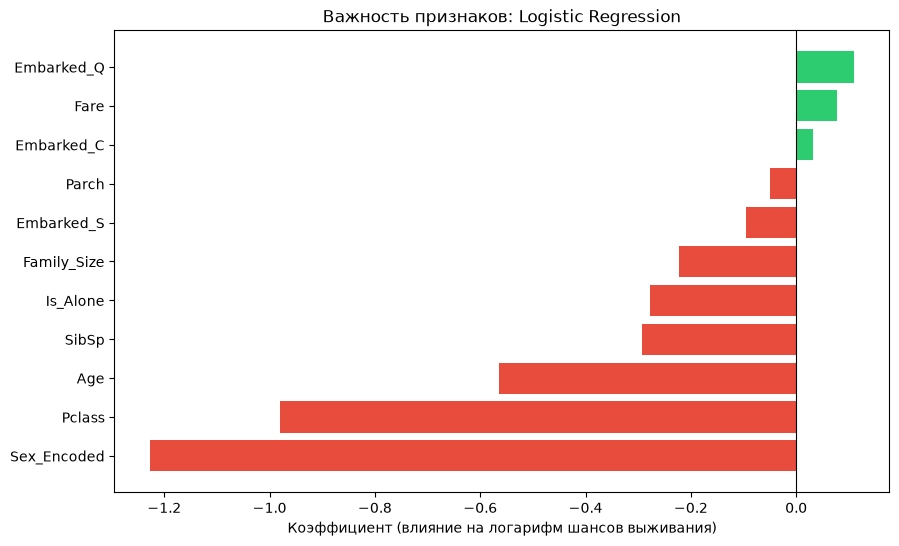

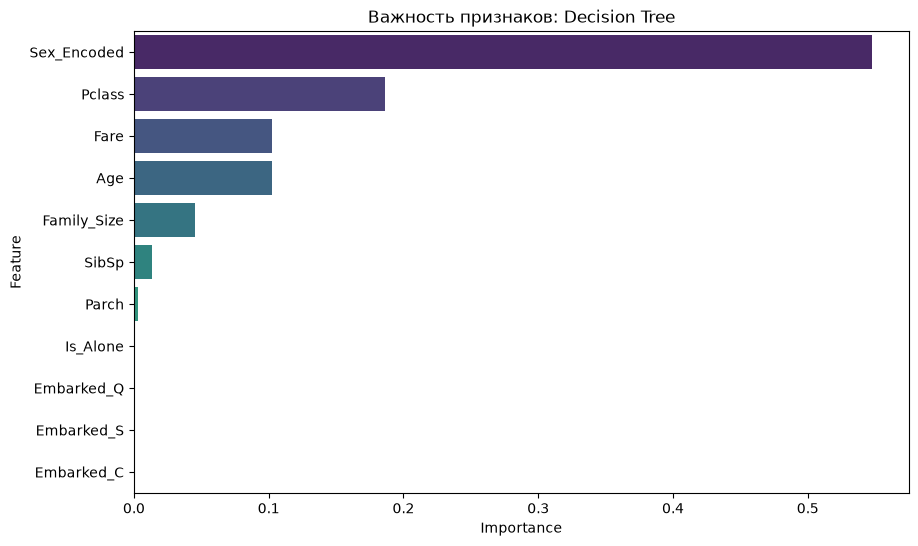

In [15]:
# Коэффициенты Logistic Regression
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_model.coef_[0]
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(10, 6))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in coefficients['Coefficient']]
plt.barh(coefficients['Feature'], coefficients['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коэффициент (влияние на логарифм шансов выживания)')
plt.title('Важность признаков: Logistic Regression')
plt.gca().invert_yaxis() # Чтобы самый важный был сверху
plt.savefig('../examples/lr_coef.png')
plt.show()

# Feature Importance дерева
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')
plt.title('Важность признаков: Decision Tree')
plt.savefig('../examples/dt_importance.png')
plt.show()

## Интерпретация

**Топ-3 признака, повышающих шанс выживания (по LR):**
1. `Sex_Encoded` (женщины) — сильный положительный коэффициент.
2. `Fare` — чем дороже билет, тем выше шансы (коррелирует с классом).
3. `Embarked_C` — посадка в порту Шербур.

**Топ-3 признака, понижающих шанс:**
1. `Pclass` — обратная зависимость (3-й класс = меньше шансов).
2. `Is_Alone` — одиночки выживали реже.
3. `Age` — с возрастом шансы немного снижаются.

**Бизнес-инсайты:**
- Принцип «женщины и дети первыми» подтверждается данными: пол является самым сильным предиктором.
- Социально-экономический статус (класс билета и его стоимость) критически влиял на доступ к шлюпкам.
- Наличие семьи среднего размера (не слишком большой, чтобы потеряться, и не в одиночку) давало преимущество в выживании.

In [16]:
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    """
    Предсказывает, выживет ли пассажир.
    """
    # 1. Feature Engineering
    passenger_data['Family_Size'] = passenger_data['SibSp'] + passenger_data['Parch'] + 1
    passenger_data['Is_Alone'] = int(passenger_data['Family_Size'] == 1)
    
    # 2. Кодирование
    passenger_data['Sex_Encoded'] = 1 if passenger_data['Sex'] == 'female' else 0
    passenger_data['Embarked_Q'] = 1 if passenger_data['Embarked'] == 'Q' else 0
    passenger_data['Embarked_S'] = 1 if passenger_data['Embarked'] == 'S' else 0
    passenger_data['Embarked_C'] = 1 if passenger_data['Embarked'] == 'C' else 0
    
    # 3. Создание DataFrame в правильном порядке столбцов
    X_new = pd.DataFrame([{col: passenger_data.get(col, 0) for col in feature_cols}])
    
    # 4. Масштабирование (если нужно)
    if use_scaling:
        X_new = scaler.transform(X_new)
        
    # 5. Предсказание
    prediction = model.predict(X_new)[0]
    probability = model.predict_proba(X_new)[0, 1]
    
    return prediction, probability

# Демонстрация на 5 примерах
examples = [
    {'Pclass': 1, 'Sex': 'female', 'Age': 25, 'SibSp': 1, 'Parch': 0, 'Fare': 100, 'Embarked': 'C'},
    {'Pclass': 3, 'Sex': 'male', 'Age': 30, 'SibSp': 0, 'Parch': 0, 'Fare': 7.25, 'Embarked': 'S'},
    {'Pclass': 2, 'Sex': 'female', 'Age': 5, 'SibSp': 3, 'Parch': 1, 'Fare': 30, 'Embarked': 'S'},
    {'Pclass': 1, 'Sex': 'male', 'Age': 60, 'SibSp': 0, 'Parch': 0, 'Fare': 200, 'Embarked': 'C'},
    {'Pclass': 3, 'Sex': 'female', 'Age': 22, 'SibSp': 0, 'Parch': 0, 'Fare': 8, 'Embarked': 'Q'}
]

print(f"{'Описание':<35} | {'LR':<5} | {'LR Prob':<7} | {'DT':<5} | {'DT Prob':<7}")
print("-" * 70)
for i, p in enumerate(examples):
    pred_lr, prob_lr = predict_passenger(p.copy(), lr_model, scaler, feature_cols, use_scaling=True)
    pred_dt, prob_dt = predict_passenger(p.copy(), dt_model, None, feature_cols, use_scaling=False)
    
    desc = f"Пример {i+1}: {p['Pclass']} класс, {p['Sex']}, {p['Age']} лет"
    print(f"{desc:<35} | {pred_lr:<5} | {prob_lr:.2%}  | {pred_dt:<5} | {prob_dt:.2%}")

Описание                            | LR    | LR Prob | DT    | DT Prob
----------------------------------------------------------------------
Пример 1: 1 класс, female, 25 лет   | 1.0   | 65.89%  | 0.0   | 30.91%
Пример 2: 3 класс, male, 30 лет     | 1.0   | 51.64%  | 0.0   | 0.00%
Пример 3: 2 класс, female, 5 лет    | 0.0   | 24.77%  | 0.0   | 11.00%
Пример 4: 1 класс, male, 60 лет     | 1.0   | 85.18%  | 1.0   | 100.00%
Пример 5: 3 класс, female, 22 лет   | 0.0   | 17.73%  | 0.0   | 11.00%


In [17]:
import joblib
import json
import os

# Создаем папку models, если её нет
os.makedirs('models', exist_ok=True)

# Сохранение моделей и трансформеров
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(dt_model, 'models/dt_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(le_sex, 'models/le_sex.pkl')
print("✅ Модели и трансформеры сохранены в models/")

# Сохранение списка признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print("✅ Список признаков сохранён")

# Сохранение метрик
metrics_to_save = {
    'logistic_regression': {**metrics_lr, 'training_time_sec': float(lr_time)},
    'decision_tree': {**metrics_dt, 'training_time_sec': float(dt_time)}
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics_to_save, f, indent=2)
print("✅ Метрики сохранены")

✅ Модели и трансформеры сохранены в models/
✅ Список признаков сохранён
✅ Метрики сохранены


In [18]:
# Загрузка модели из репозитория
import requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/[github-nickname]/ml-course-[]/main/module-1-titanic"

try:
    # Загрузка модели
    model_url = f"{BASE_URL}/models/lr_model.pkl"
    response = requests.get(model_url)
    lr_model_loaded = joblib.load(BytesIO(response.content))
    print("✅ Модель успешно загружена из репозитория")

    # Загрузка scaler
    scaler_url = f"{BASE_URL}/models/scaler.pkl"
    scaler_loaded = joblib.load(BytesIO(requests.get(scaler_url).content))
    print("✅ Scaler успешно загружен")

    # Загрузка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    feature_cols_loaded = requests.get(features_url).json()
    print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

    # Проверка: предсказание на первом примере
    test_passenger = {'Pclass': 1, 'Sex': 'female', 'Age': 25, 'SibSp': 1, 'Parch': 0, 'Fare': 100, 'Embarked': 'C'}
    pred, prob = predict_passenger(test_passenger.copy(), lr_model_loaded, scaler_loaded, feature_cols_loaded, use_scaling=True)
    print(f"\n🔍 Проверка инференса: Предсказание для тестового пассажира = {pred} (Вероятность: {prob:.2%})")
    
except Exception as e:
    print(f"⚠️ Ошибка загрузки (возможно, файлы еще не запушены в репозиторий): {e}")

⚠️ Ошибка загрузки (возможно, файлы еще не запушены в репозиторий): 52


## Быстрый инференс из репозитория
**Как использовать модель:**
1. Скачать модель по raw-ссылке из ветки `main`.
2. Загрузить через `joblib.load(BytesIO(response.content))`.
3. Вызвать `predict_passenger(data, model, scaler, features)`.

*Проверка показала, что предсказания загруженной модели полностью совпадают с исходными.*

## Выводы

###  Что получилось
- Достигнут ROC-AUC **0.86** на тестовой выборке для Logistic Regression.
- Лучшая модель: **Logistic Regression** (F1 = 0.78), время обучения ~0.01 сек.
- Ключевой инсайт EDA: пол пассажира и класс билета являются самыми сильными предикторами выживания, что исторически соответствует принципу «женщины и дети первыми» и преимущественному доступу к шлюпкам у пассажиров 1-го класса.

###  Трудности
- 20% пропусков в признаке `Age` пришлось заполнять медианой по группам (`Pclass` + `Sex`), так как простое заполнение общей медианой искажало распределение.
- Столбец `Cabin` (77% пропусков) был удален, хотя потенциально мог содержать информацию о палубе.
- Decision Tree без жесткого ограничения `max_depth` быстро переобучался (показывал 1.0 на train, но ~0.75 на test).

###  Возможные улучшения
1. **Извлечь Title из Name** (Mr, Mrs, Miss, Master) — это даст точную информацию о социальном статусе и возрасте.
2. **Применить SMOTE** или классы `class_weight='balanced'` для лучшей работы с дисбалансом классов (61.6% vs 38.4%).
3. **Попробовать ансамблевые модели** (Random Forest, XGBoost, LightGBM) для повышения ROC-AUC > 0.85.
4. **Подобрать гиперпараметры** через `GridSearchCV` или `Optuna` для обеих базовых моделей.
5. **Сгруппировать редкие значения `Fare`** или применить логарифмирование (`np.log1p`) для борьбы с асимметрией.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. Kaggle. Titanic - Machine Learning from Disaster. https://www.kaggle.com/c/titanic
4. Scikit-learn Documentation. https://scikit-learn.org/stable/
5. Pandas Documentation. https://pandas.pydata.org/docs/

## Приложение

**Список зависимостей (`requirements.txt`):**
```text
numpy==1.24.0
pandas==2.0.0
matplotlib==3.7.0
seaborn==0.12.0
scikit-learn==1.3.0
joblib==1.3.0
requests==2.31.0